<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Introduction and overview of machine learning concepts

##Script 1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [ ]:
#load, clean, and visualize Iris data set
#the species labels as integer codes (0, 1, 2)
iris_raw = load_iris()

#dataframe df
df = pd.DataFrame(data=iris_raw.data, columns=iris_raw.feature_names)

#mapping the species labels back to the
#actual species names so the plot legend reads "setosa" instead of "0"
df['species'] = pd.Categorical.from_codes(iris_raw.target, iris_raw.target_names)

df = df.rename(columns={
    'sepal length (cm)': 'sepal_length',
    'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length',
    'petal width (cm)': 'petal_width',
})

print("Raw data loaded. Shape (rows, columns):", df.shape)
print(df.head(), "\n")

Raw data loaded. Shape (rows, columns): (150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa 



In [ ]:
#dropping all rows where sepal length is greater than 5 (cm)
before_count = len(df)
df_clean = df[df['sepal_length'] <= 5].copy()
after_count = len(df_clean)

print(f"Filtering complete: kept {after_count} of {before_count} flowers "
      f"(removed {before_count - after_count} with sepal length > 5 cm).\n")
print(df_clean['species'].value_counts(), "\n")

Filtering complete: kept 32 of 150 flowers (removed 118 with sepal length > 5 cm).

species
setosa        28
versicolor     3
virginica      1
Name: count, dtype: int64 



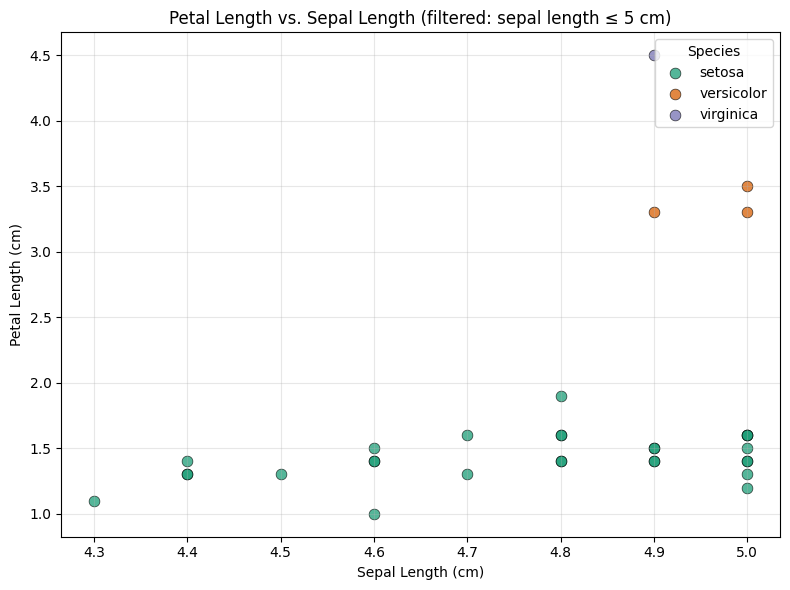

In [ ]:
#scatter plot of petal length vs. sepal length, colored by species
#one dot per flower
#we are placing sepal length on the x-axis and petal length on the y-axis,
#so each dot's position tells us
#both measurements for a single flower.
species_colors = {
    'setosa': '#1b9e77',
    'versicolor': '#d95f02',
    'virginica': '#7570b3',
}

fig, ax = plt.subplots(figsize=(8, 6))

for species_name, group in df_clean.groupby('species', observed=True):
    ax.scatter(
        group['sepal_length'],
        group['petal_length'],
        label=species_name,
        color=species_colors[species_name],
        alpha=0.75,
        edgecolor='black',
        linewidth=0.5,
        s=60,
    )

ax.set_xlabel('Sepal Length (cm)')
ax.set_ylabel('Petal Length (cm)')
ax.set_title('Petal Length vs. Sepal Length (filtered: sepal length ≤ 5 cm)')
ax.legend(title='Species')
ax.grid(True, alpha=0.3)

plt.tight_layout()

##Script 2

In [ ]:
#load, clean, and visualize MNIST handwritten digits dataset
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#load the MNIST dataset into a pandas DataFrame
#CLAUDE Suggested code

DATA_DIR = "mnist_data"
ZIP_PATH = os.path.join(DATA_DIR, "mnist_test.csv.zip")
CSV_PATH = os.path.join(DATA_DIR, "mnist_test.csv")
SOURCE_URL = "https://github.com/phoebetronic/mnist/raw/main/mnist_test.csv.zip"

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(CSV_PATH):
    if not os.path.exists(ZIP_PATH):
        print(f"Downloading MNIST CSV from {SOURCE_URL} ...")
        urllib.request.urlretrieve(SOURCE_URL, ZIP_PATH)
    print("Extracting CSV from zip archive ...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extract("mnist_test.csv", DATA_DIR)

#column names: the first column:: digit label,
#the remaining 784 columns are pixel intensities,
#which corresponds to a flattened 28x28 grid read left-to-right, top-to-bottom
column_names = ["label"] + [f"pixel{i}" for i in range(784)]

df = pd.read_csv(CSV_PATH, header=None, names=column_names)

print(f"Loaded DataFrame shape: {df.shape}")
print(f"  -> {df.shape[0]} images, {df.shape[1] - 1} pixel columns + 1 label column")
print(f"Label distribution across all digits:\n{df['label'].value_counts().sort_index()}\n")

Loaded DataFrame shape: (10000, 785)
  -> 10000 images, 784 pixel columns + 1 label column
Label distribution across all digits:
label
0     980
1    1135
2    1032
3    1010
4     982
5     892
6     958
7    1028
8     974
9    1009
Name: count, dtype: int64



In [ ]:
#drop all digits except 3 and 8
df_38 = df[df["label"].isin([3, 8])].reset_index(drop=True)

print(f"After filtering to digits 3 and 8: {df_38.shape[0]} images remain")
print(f"  -> 3s: {(df_38['label'] == 3).sum()}, 8s: {(df_38['label'] == 8).sum()}\n")

After filtering to digits 3 and 8: 1984 images remain
  -> 3s: 1010, 8s: 974



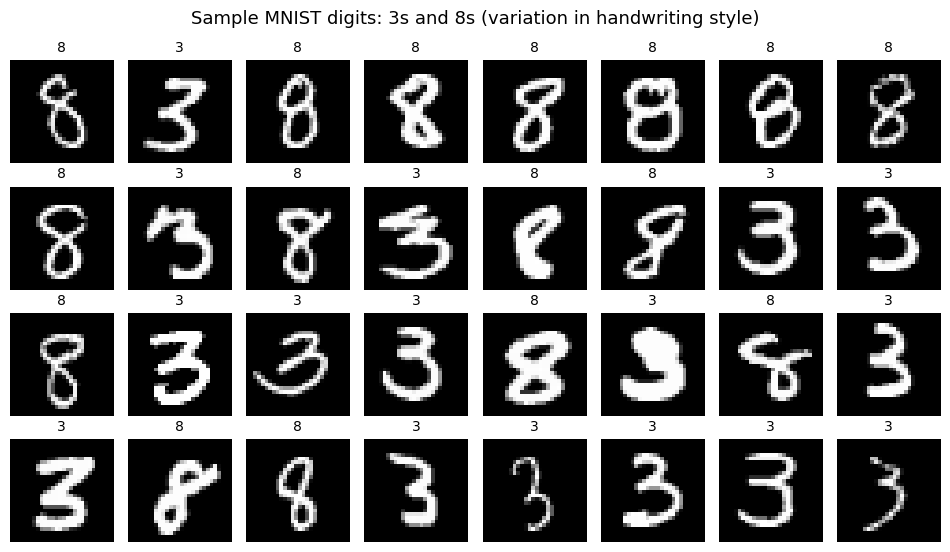

In [ ]:
#visualize a grid of MNIST digits to see handwriting variation

#for each axis:
# Take in input of one row's 784 pixel values as a NumPy array.
# use .reshape(28, 28) which folds that flat list back into the original
#   28x28 spatial grid (undoing the flattening done when the CSV
#   was created).
# imshow() generates/ renders the 2D array as an image,
#   mapping pixel value 0 to black and 255 to white

#32 example digits total, a mix of 3s and 8s
n_rows, n_cols = 4, 8
n_examples = n_rows * n_cols

#a half split: half 3s, half 8s, sampled at random for proper variation
threes = df_38[df_38["label"] == 3].sample(n=n_examples // 2, random_state=42)
eights = df_38[df_38["label"] == 8].sample(n=n_examples // 2, random_state=42)
sample = pd.concat([threes, eights]).sample(frac=1, random_state=1).reset_index(drop=True)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.2, n_rows * 1.4))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    # to store 784 pixel values
    pixels = row[1:].to_numpy(dtype=np.uint8)
    # project back into a 28x28 grid
    image = pixels.reshape(28, 28)
    ax.imshow(image, cmap="gray")
    ax.set_title(str(row["label"]), fontsize=10)
    ax.axis("off")

fig.suptitle("Sample MNIST digits: 3s and 8s (variation in handwriting style)", fontsize=13)
fig.tight_layout()